(lyzenga-recalc)=
# Impedance Match For Lyzenga et al. 1983 Data

<b>NOTE</b>

* Some data points have no impact conditions and only report Pressure and Temperature. So no Us-Up or density information.
* Data points are a mix of z-cut and perpendicular to z-cut (unknown) orientation. One point has no description of orientation. See table below.

 

In [1]:
#@title Double-click to collapse code
%matplotlib inline
import os
from os.path import exists

# Collect files needed to run this notebook in the cloud (e.g., Google CoLab)
use_local_files = True # prefer local files than GitHub repo (change to false to refresh from repo)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os
from os.path import exists

# Impedance Match Calculation classes and functions
import IM_module as IM # classes and functions for this impedance match notebook
from scipy import linalg
from copy import deepcopy

# customized python classes and functions for EOS data
import hpeos_module as hp # holds shock Hugoniot python class
import pickle

# date & time used for unique output file name below
from datetime import datetime
print("Date and time: ", datetime.now())


Date and time:  2024-08-03 10:17:47.633472


## Choose load pickle file or re-run Monte Carlo Impedance Match

When compiled for the Jupyterbook, using N=50. 

N=1000 run used for error bars and plots at the bottom.


In [2]:
# Run the MC again
RUNMC = True
# Load the pickle file; do not run; set to False to compile the Jupyterbook
#RUNMC = False

# set number of IM calcs
#N=50
N=1000


## Load the material database

In [3]:
# load the materials data table; change matfilename if not using default
matdata, imat = IM.ReadMaterials(matfilename='materials-data.csv')

display(matdata)

,Material,Density(kg/m3),rho0_err,c0(m/s),c0_err,s1,s1_err,s2(s/m),s2_err,d(s/m),d_err,g0,g0_err,q,q_err,up_low(m/s),up_high(m/s),IHED_id,Date,Notes
0,Tantalum2023,16649.0,-1,3289.00000,0.025,1.313000,0.011,0.000000,-1.0,0.000000,0.0,1.62,-1,1.00,-1,0.0,-1.0,75,2023-09-10,AGU Reference Shelf+Katahara et al. 1979+Cohen...
1,Steel304-l2,7870.0,-1,4580.00000,-1.000,1.490000,-1.000,0.000000,-1.0,0.000000,0.0,2.20,-1,1.00,-1,170.0,3607.0,347,2023-09-04,STS refit Duffy+IHED RECOMMENDED
2,Fused-qtz-stv,2204.0,-1,1382.81770,-1.000,1.535125,-1.000,0.000000,0.0,0.000000,0.0,0.65,-1,1.00,-1,2800.0,4000.0,143,2023-09-04,STS fit to stv region RECOMMENDED
3,qtz-CaCl2-region,2650.0,-1,1797.25088,-1.000,1.688354,-1.000,0.000000,-1.0,0.000000,0.0,1.00,-1,1.00,-1,0.0,-1.0,174,2023-09-04,Stewart fit CaCl2 region RECOMMENDED
4,Aluminium 6061,2683.0,-1,5349.00000,-1.000,1.338000,-1.000,0.000000,-1.0,0.000000,0.0,1.00,-1,1.00,-1,-1.0,-1.0,324,2022-11-11,Duffy & Ahrens 1998 NEED TO ADD Z data
5,Steel 304,7870.0,-1,4580.00000,-1.000,1.490000,-1.000,0.000000,-1.0,0.000000,0.0,2.20,-1,1.00,-1,209.0,1485.0,347,2022-11-11,Duffy & Ahrens 1998
6,Steel304-q,7870.0,-1,4579.00000,-1.000,1.533428,-1.000,-0.000014,-1.0,0.000000,0.0,2.20,-1,1.00,-1,170.0,4730.0,347,2022-11-11,STS refit Duffy+IHED 9/4/2023 NOT RECOMMENDED
7,Copper,8924.0,-1,3975.00000,-1.000,1.471000,-1.000,-0.000005,-1.0,0.000000,0.0,1.96,-1,1.00,-1,0.0,40800.0,45,2022-11-11,IHED fit; g0 Gilev 2018 and q is quess
8,Tantalum,16649.0,-1,3310.00000,-1.000,1.306000,-1.000,0.000000,-1.0,0.000000,0.0,1.62,-1,1.00,-1,0.0,-1.0,75,2022-11-11,AGU Reference Shelf+Katahara et al. 1979+Cohen...
9,Tungsten,19235.0,-1,3994.00000,-1.000,1.278800,-1.000,-0.000005,-1.0,0.000000,0.0,1.81,-1,0.71,-1,0.0,16450.0,79,2022-11-11,IHED fit and Litasov 2013 for gamma


## Set up the materials and uncertainties - MKS UNITS

covariance matrices are from Hugoniot fits

currently all linear fits -- need to update IM_module for other forms

<bold>mat3 needs correct density and uncertainty in the material initialization</bold>


In [4]:
# everything in mks

# set up independent particle velocity array
up =np.arange(501)/500*10000

# initialize materials used in this notebook
# flyer
Ta2023a = IM.Material() # create material object named 'mat3'
matname='Tantalum2023' # material name in the material-data.csv file
Ta2023a.DefineParamsID(matname,matdata,imat) # load the parameters for this material
Ta2023a.MakeHugoniot(up)
Ta2023a.rho0_err = 10
Ta2023a.cov = np.asarray([[ 1.31441527e-04, -2.62935631e-01],       [-2.62935631e-01,  6.24772442e+02]])
Ta2023a.lmat = linalg.cholesky(Ta2023a.cov,lower=True)

# driver
Ta2023b = IM.Material() # create material object named 'mat3'
matname='Tantalum2023' # material name in the material-data.csv file
Ta2023b.DefineParamsID(matname,matdata,imat) # load the parameters for this material
Ta2023b.MakeHugoniot(up)
Ta2023b.rho0_err = 10
Ta2023b.cov = np.asarray([[ 1.31441527e-04, -2.62935631e-01],       [-2.62935631e-01,  6.24772442e+02]])
Ta2023b.lmat = linalg.cholesky(Ta2023b.cov,lower=True)

# target FQ stv region
FQstv = IM.Material() # create material object named 'mat3'
matname='Fused-qtz-stv' # material name in the material-data.csv file
FQstv.DefineParamsID(matname,matdata,imat) # load the parameters for this material
FQstv.MakeHugoniot(up)
FQstv.rho0_err = 10
FQstv.cov = np.asarray([[ 0.0065196 , -0.02354445],[-0.02354445,  0.08556451]])
FQstv.lmat = linalg.cholesky(FQstv.cov,lower=True)

# target QTZ CaCl2 region
QTZcacl2 = IM.Material() # create material object named 'mat3'
matname='qtz-CaCl2-region' # material name in the material-data.csv file
QTZcacl2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
QTZcacl2.MakeHugoniot(up)
QTZcacl2.rho0_err = 10
QTZcacl2.cov = np.asarray([[ 0.00019996, -0.00083886],[-0.00083886,  0.00353192]])
QTZcacl2.lmat = linalg.cholesky(QTZcacl2.cov,lower=True)


## Load shot dataset

Loading initial density, flyer velocity, shock velocity, temperatures


In [5]:
sio2dat = pd.read_csv('lyzenga-all.csv')


In [6]:
display(sio2dat)

,shot,sample,rho0,rho0_std,uflyer,uflyer_std,uflyer_source,us,us_std,us_source,orientation,T,T_std,T_source,T_rel,T_rel_std,T_rel_source,P,P_std,Notes
0,Q1,Perp Z-cut Alpha Quartz,2.648,0.002,5.172,0.007,xray,8.64,0.06,pyrometry,a,5430.0,120.0,Boslough88,3920.0,70.0,Boslough88,92.5,1.0,Pressures from Lyzenga et al. 1983
1,Q2,Z-cut Alpha Quartz,2.648,0.002,5.620,0.010,xray,9.27,0.16,pyrometry,b,5900.0,200.0,Boslough88,0.0,0.0,NaN,106.5,1.9,"Probably same as 107.8 P,T point; assumed to b..."
2,Q3,Unknown Alpha Quartz,2.648,0.002,5.871,0.010,xray,9.73,0.06,streak camera,NaN,0.0,0.0,NaN,0.0,0.0,NaN,116.0,1.4,Reported in Table 3; no orientation info; no pyro
3,Q4,Z-cut Alpha Quartz,2.648,0.002,5.926,0.011,xray,9.70,0.12,pyrometry,b,4910.0,110.0,Boslough88,3890.0,110.0,Boslough88,116.5,1.0,a=shock perpendicular to (0001) axis
4,Q5,Perp Z-cut Alpha Quartz,2.648,0.002,6.297,0.012,xray,9.82,0.10,pyrometry,a,5320.0,90.0,Boslough88,4150.0,20.0,Boslough88,126.6,1.0,b=shock paraelle to (0001) axis=z cut
5,Q6,Z-cut Alpha Quartz,2.648,0.002,6.600,0.012,xray,10.30,0.10,pyrometry,b,5760.0,90.0,Boslough88,0.0,0.0,Boslough88,137.0,1.0,NaN
6,QT1,Perp Z-cut Alpha Quartz,2.648,0.002,0.000,0.000,NaN,0.00,0.00,NaN,a,4440.0,40.0,Boslough88,0.0,0.0,Boslough88,75.9,0.8,NaN
7,QT2,Z-cut Alpha Quartz,2.648,0.002,0.000,0.000,NaN,0.00,0.00,NaN,b,4850.0,130.0,Boslough88,3660.0,40.0,Boslough88,85.9,1.0,NaN
8,QT3,Perp Z-cut Alpha Quartz,2.648,0.002,0.000,0.000,NaN,0.00,0.00,NaN,a,5630.0,140.0,Boslough88,4000.0,80.0,Boslough88,99.3,1.0,NaN
9,QT4,Perp Z-cut Alpha Quartz,2.648,0.002,0.000,0.000,NaN,0.00,0.00,NaN,a,6100.0,190.0,Boslough88,0.0,0.0,Boslough88,109.7,1.0,NaN


## IM function usage

set 3 materials and 3 variables: velpair, uspair, N

impact velocity and error:
    velpair = [5000,50] # m/s, error
    
shock velocity measurement and error:
    uspair = [6000,100] # m/s error

for forward calculation with known Hugoniots:
    uspair = [0,0] # no shock velocity; use forward calculation

set number of iterations N

Example:
```
velpair = [5000,50] # m/s, error
uspair = [6000,100] # m/s error
N=100
result = IM.MCIM('ShotXX',Ta2023a,Ta2023b,FQstv,N,velpair,uspair,up,plots=True)
print(result)
```

Expand these cells to see the MC code and output plots:

In [7]:
%%capture cap --no-stderr
# above command captures the output so can be saved to a file; it is displayed below

if RUNMC:
    
    shotlist=np.asarray(sio2dat.loc[:,["shot"]])
    mat1 = deepcopy(Ta2023a)
    mat2 = deepcopy(Ta2023b)
    
    silicadata_list = []
    for count in range(len(shotlist)):
        shotnum = shotlist[count][0]
        row=count
        if (sio2dat.loc[row,'sample'] == 'Fused Silica'):
            print('Fused silica')
            mat3 = deepcopy(FQstv)    
        else:
            print('Quartz')
            mat3 = deepcopy(QTZcacl2)
        mat3.rho0 = sio2dat.loc[row,'rho0']*1000 # mks
        mat3.rho0_err = sio2dat.loc[row,'rho0_std']*1000 # mks
    
        name = 'shot'+str(shotnum)
        # all should be same each time from here on out
        shotx=None
        #list=sio2dat.loc[:,["shot"]]
        #row = np.where(list == name)[0][0]
        #print(row)
        print(sio2dat.loc[row,:])
        print(sio2dat.loc[row,'us'])
        
        shotx = hp.HPeos_Shock()
        shotx.ref=[name]
        shotx.material=[sio2dat.loc[row,'sample']]
        shotx.rem=[sio2dat.loc[row,'T_source']]
        shotx.orientation=[sio2dat.loc[row,'orientation']]
        shotx.calcinfo=[sio2dat.loc[row,'Notes']]
        shotx.T = [sio2dat.loc[row,'T']]
        shotx.T_std = [sio2dat.loc[row,'T_std']]
        shotx.T_rel = [sio2dat.loc[row,'T_rel']]
        shotx.T_rel_std = [sio2dat.loc[row,'T_rel_std']]
        shotx.uflyer=[sio2dat.loc[row,'uflyer']]
        shotx.uflyer_std=[sio2dat.loc[row,'uflyer_std']]
        shotx.uflyer_units=['km/s']
        shotx.us = [sio2dat.loc[row,'us']]
        shotx.us_std = [sio2dat.loc[row,'us_std']]
        shotx.us_units=['km/s']
        
        velpair = [shotx.uflyer[0]*1000.,shotx.uflyer_std[0]*1000.] # m/s, error
        uspair = [shotx.us[0]*1000.,shotx.us_std[0]*1000.] # m/s error
    
        if shotx.uflyer[0] > 0:
            # mks in and out
            print(mat3.rho0,mat3.rho0_err)
            result = IM.MCIM(str(name),mat1,mat2,mat3,N,velpair,uspair,up,plots=True)
            print(result)
            shotx.P=[result.p2/1.e9]
            shotx.P_std = [result.p2_std/1.e9]
            shotx.P_units = ['GPa']
            shotx.up=[result.up2/1.e3]
            shotx.up_std = [result.up2_std/1.e3]
            shotx.up_units = ['km/s']
            shotx.rho=[result.rho2/1.e3]
            shotx.rho_std = [result.rho2_std/1.e3]
            shotx.rho_units = ['g/cm3']
        else:
            shotx.P=[sio2dat.loc[row,'P']]
            shotx.P_std = [sio2dat.loc[row,'P_std']]
            shotx.P_units = ['GPa']
            shotx.up=[0]
            shotx.up_std = [0]
            shotx.up_units = ['km/s']
            shotx.rho=[0]
            shotx.rho_std = [0]
            shotx.rho_units = ['g/cm3']
    
        dict(shotx)
        silicadata_list.append(shotx)
        

    lyzengadata_list = deepcopy(silicadata_list)
    # save the shock impedance match data to disk using pickle       
    with open('lyzengadata.pkl','wb') as f:
        pickle.dump(lyzengadata_list,f)  
    print('saving lyzengadata.pkl')
else:
    # load previously saved picked data
    with open('lyzengadata.pkl','rb') as f:
        lyzengadata_list=pickle.load(f)



date and time = 20240803-101939
Output file name = MCIM-Lyzenga-silica-output-20240803-101939.txt
Quartz
shot                                             Q1
sample                      Perp Z-cut Alpha Quartz
rho0                                          2.648
rho0_std                                      0.002
uflyer                                        5.172
uflyer_std                                    0.007
uflyer_source                                  xray
us                                             8.64
us_std                                         0.06
us_source                                 pyrometry
orientation                                       a
T                                            5430.0
T_std                                         120.0
T_source                                 Boslough88
T_rel                                        3920.0
T_rel_std                                      70.0
T_rel_source                             Boslough88
P          

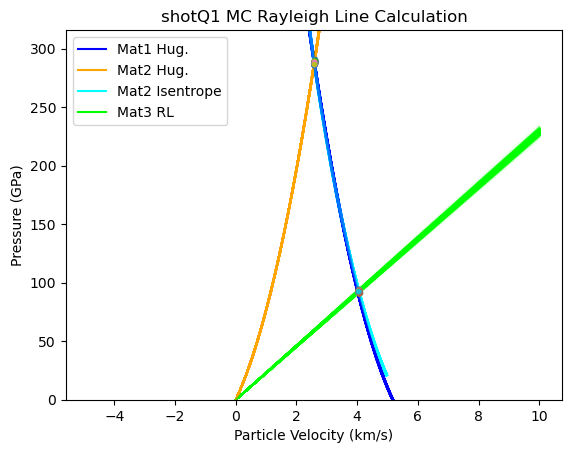

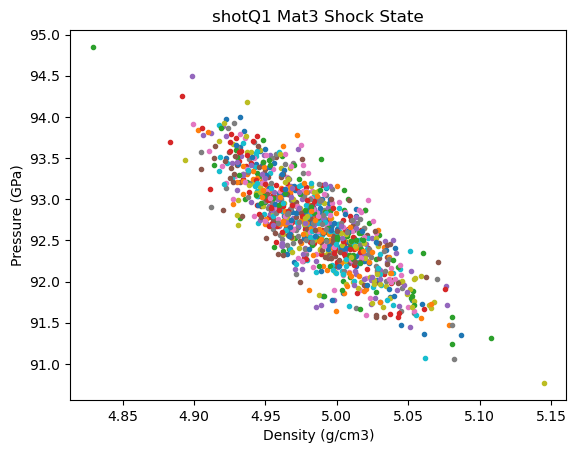

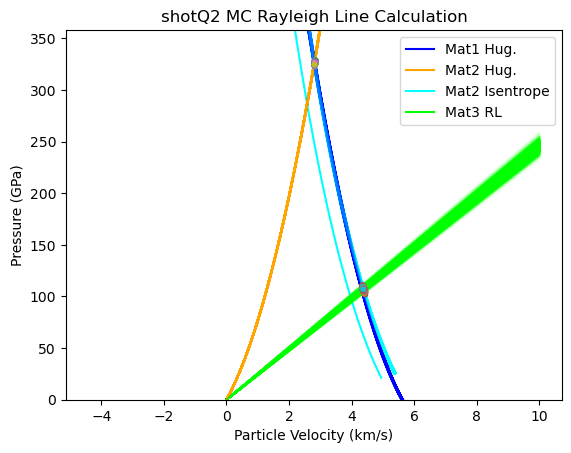

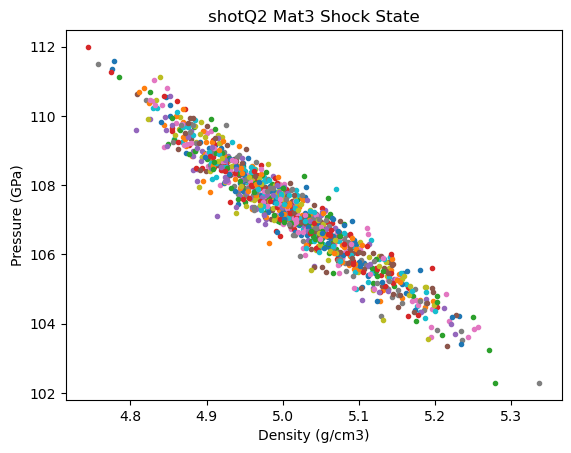

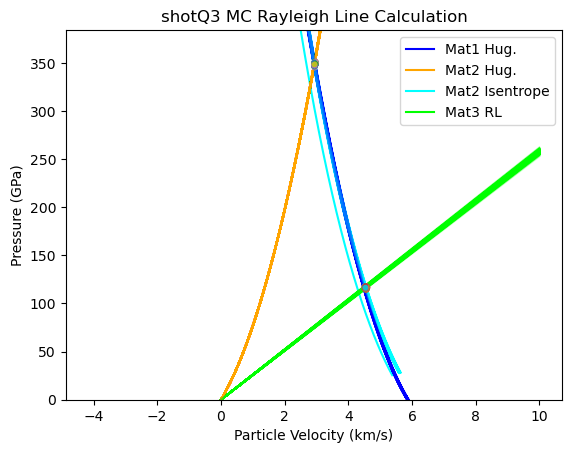

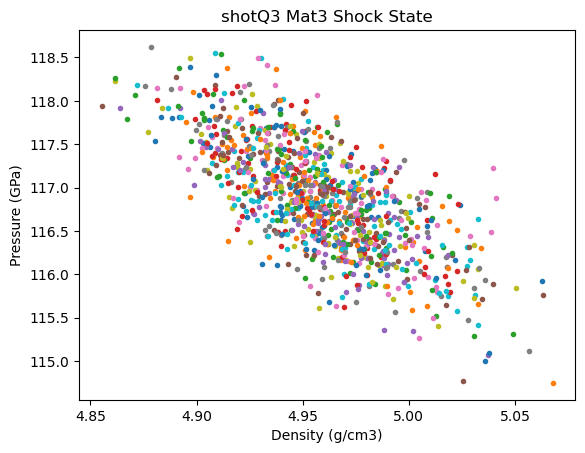

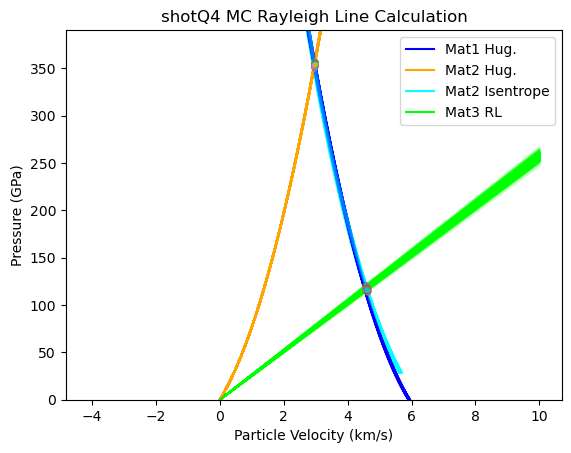

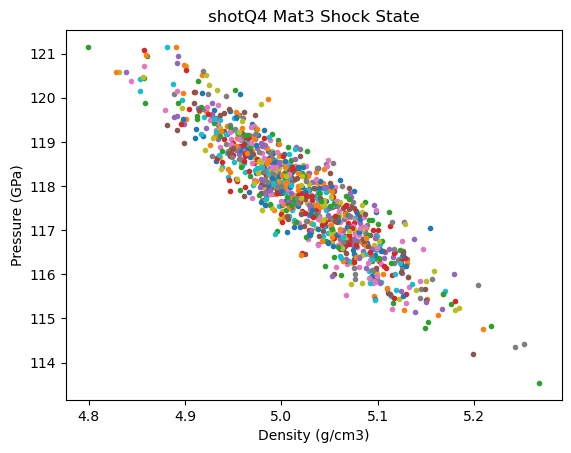

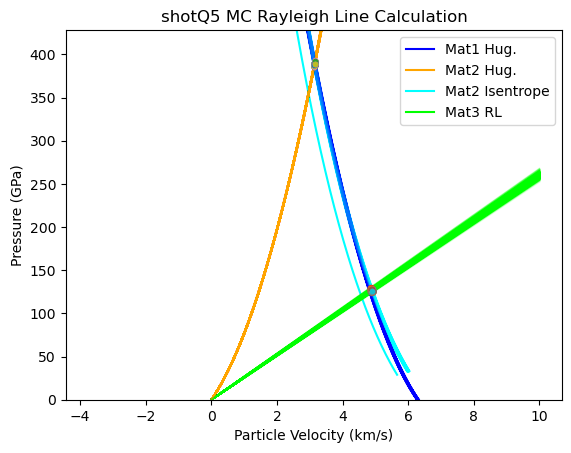

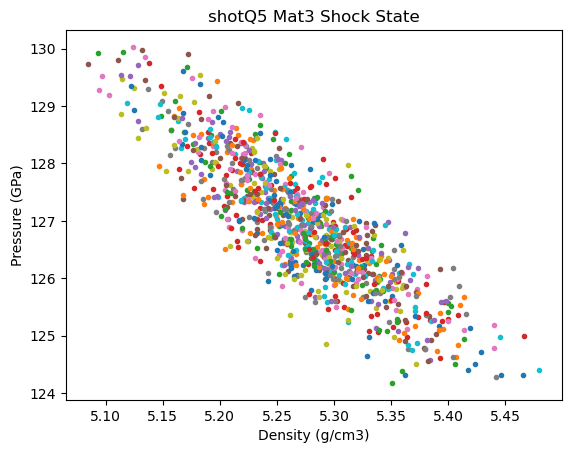

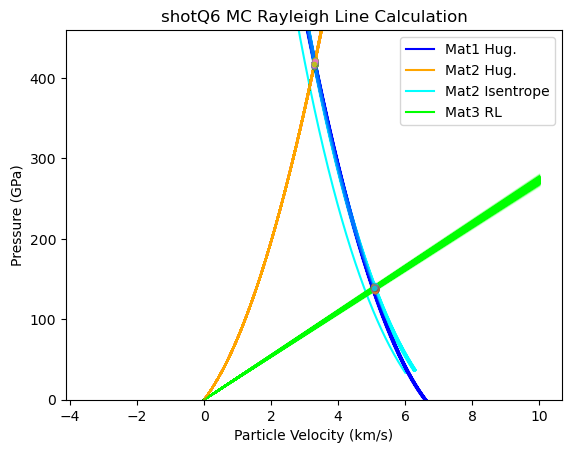

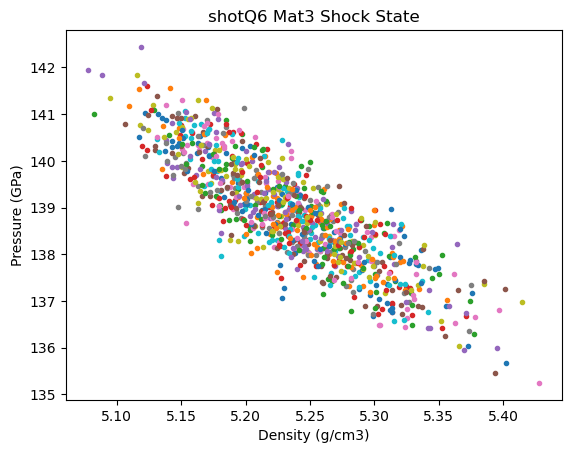

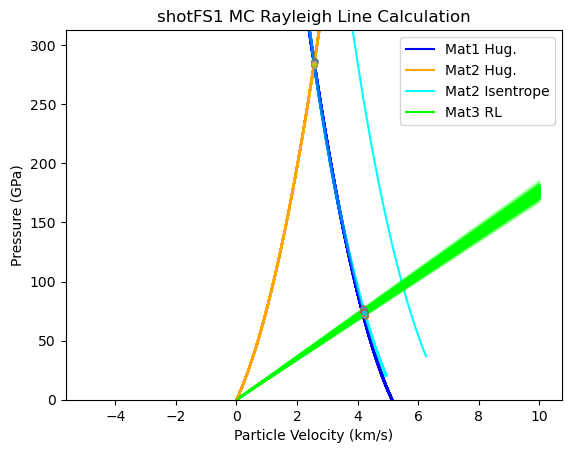

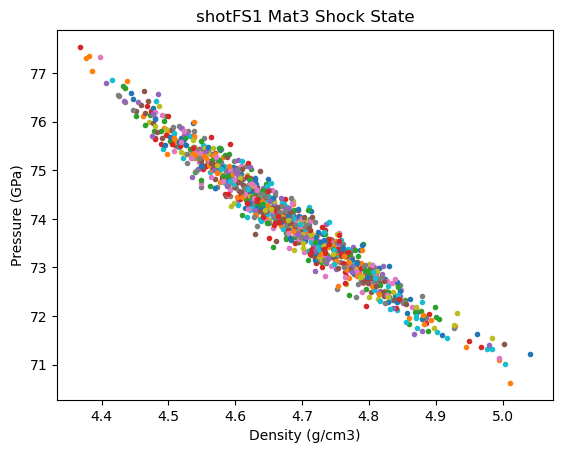

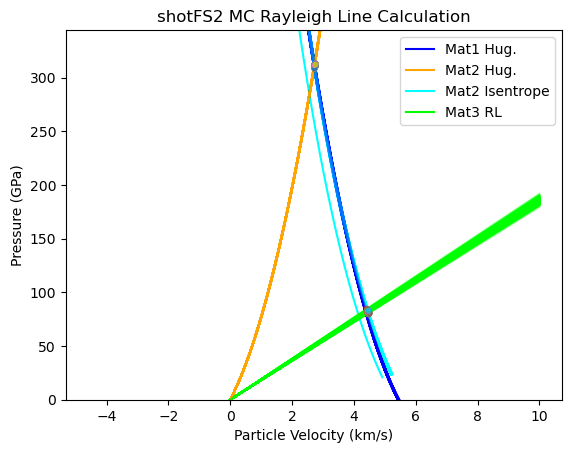

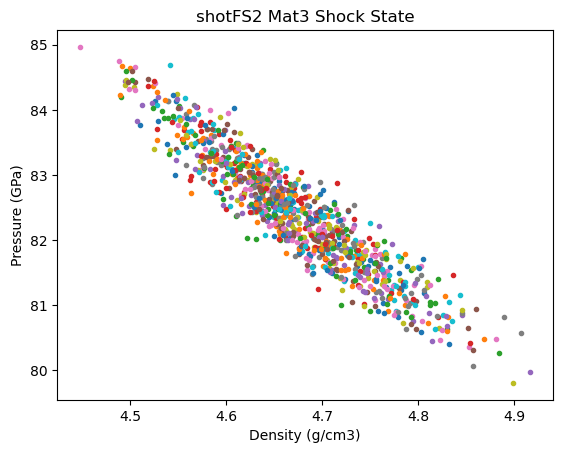

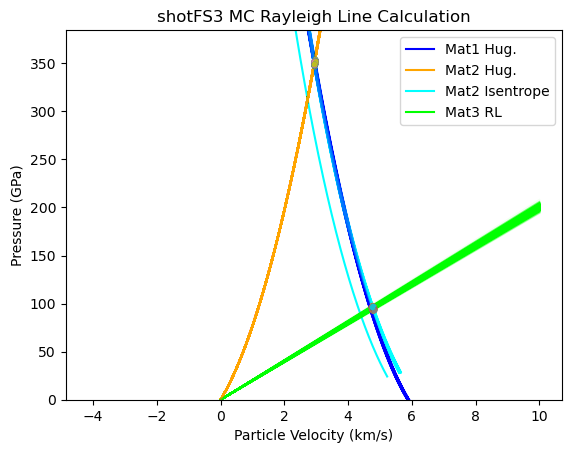

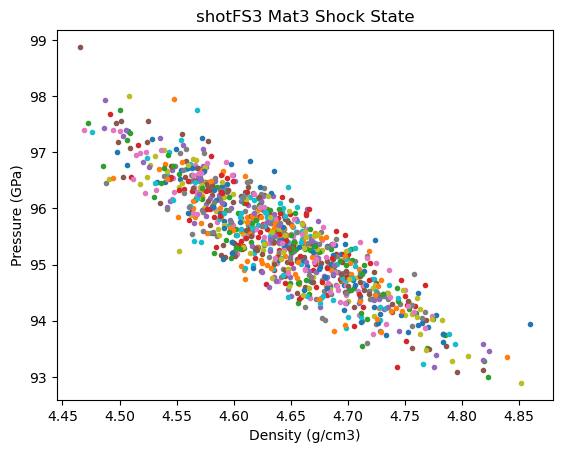

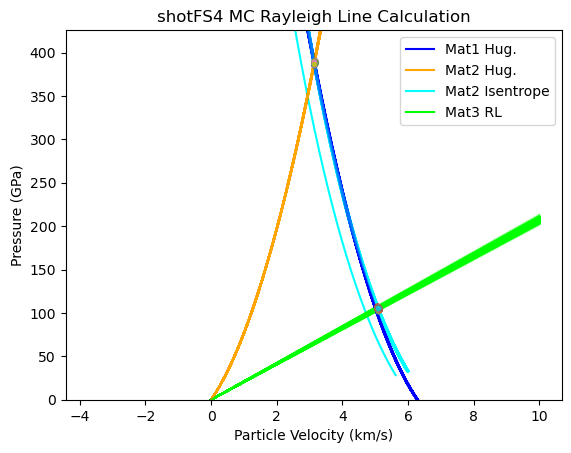

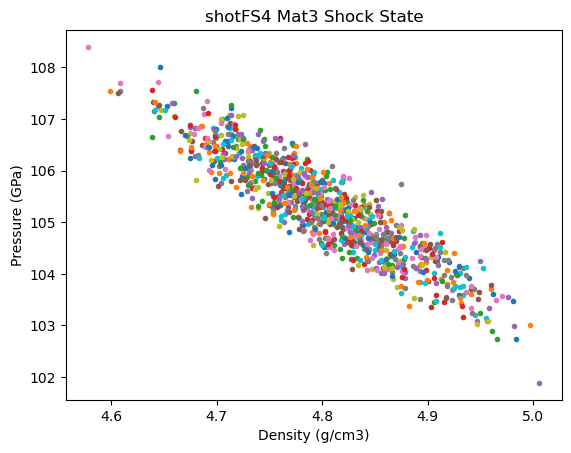

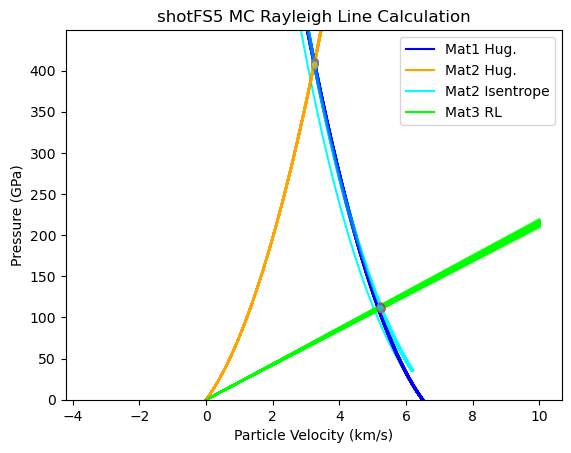

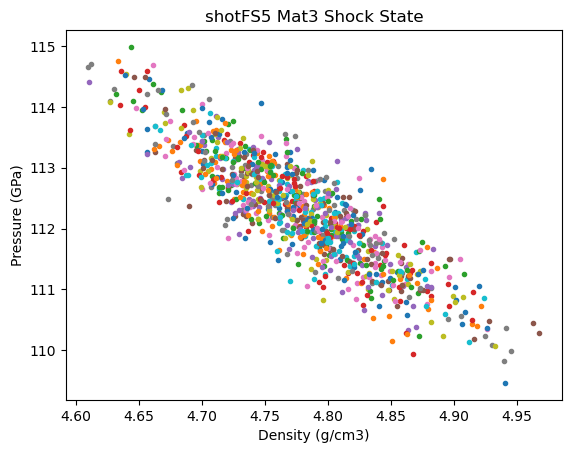

In [8]:
# write output in previous cell to text file
# unique file name for date and time to prevent over-writing output files
# datetime object containing current date and time
now = datetime.now()
#print("now =", now)
# YYmmdd-H-M-S
dt_string = now.strftime("%Y%m%d-%H%M%S")
print("date and time =", dt_string)
outputfilename = 'MCIM-Lyzenga-silica-output-'+dt_string+'.txt'
print('Output file name = '+outputfilename)

with open(outputfilename, 'w') as f:
    f.write(cap.stdout)

# The output in the previous cell is written to a text file and plot files
# print txt and images here for the notebook
cap.show()


In [9]:
## Load previous calculation N=1000
# load previously saved picked data
with open('lyzengadata-N1000.pkl','rb') as f:
    lyzengadata_list=pickle.load(f)


## Plot the results

PDV + MAVIS gives impressively small error bars.

In [10]:
qtz_list = []
fs_list = []
qtz_p_list = []
fs_p_list = []
for i in range(len(lyzengadata_list)):
    print(i,lyzengadata_list[i].material[0],lyzengadata_list[i].ref[0],lyzengadata_list[i].P[0],lyzengadata_list[i].P_std[0],lyzengadata_list[i].T[0])
    if (lyzengadata_list[i].material[0] == 'Fused Silica'):
        fs_list.append(lyzengadata_list[i])
        fs_p_list.append(lyzengadata_list[i].P[0])
    else:
        qtz_list.append(lyzengadata_list[i])
        qtz_p_list.append(lyzengadata_list[i].P[0])



0 Perp Z-cut Alpha Quartz shotQ1 92.64844931220907 0.5510818374489355 5430.0
1 Z-cut Alpha Quartz shotQ2 107.25686863340378 1.463044523790202 5900.0
2 Unknown Alpha Quartz shotQ3 116.88356070998327 0.6102598789012035 0.0
3 Z-cut Alpha Quartz shotQ4 117.77935508769322 1.14227885916705 4910.0
4 Perp Z-cut Alpha Quartz shotQ5 126.98567628909252 1.0173081417772054 5320.0
5 Z-cut Alpha Quartz shotQ6 138.87270554014185 1.1547106561537688 5760.0
6 Perp Z-cut Alpha Quartz shotQT1 75.9 0.8 4440.0
7 Z-cut Alpha Quartz shotQT2 85.9 1.0 4850.0
8 Perp Z-cut Alpha Quartz shotQT3 99.3 1.0 5630.0
9 Perp Z-cut Alpha Quartz shotQT4 109.7 1.0 6100.0
10 Fused Silica shotFS1 74.12312128904783 1.0991784768894064 4620.0
11 Fused Silica shotFS2 82.4743572355994 0.9032653514749637 5080.0
12 Fused Silica shotFS3 95.43049295509688 0.8817418492124541 5770.0
13 Fused Silica shotFS4 105.26740996000663 0.9656773268370443 6530.0
14 Fused Silica shotFS5 112.32791663723798 0.9015149407101773 7080.0
15 Fused Silica shot

Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
shotQT1 75.9 4440.0 ['Boslough88'] 0.0 0.0 0.0 0.0
shotQT2 85.9 4850.0 ['Boslough88'] 0.0 0.0 0.0 0.0
shotQ1 92.64844931220907 5430.0 ['Boslough88'] 5.172 0.007 8.64 0.06
shotQT3 99.3 5630.0 ['Boslough88'] 0.0 0.0 0.0 0.0
shotQ2 107.25686863340378 5900.0 ['Boslough88'] 5.62 0.01 9.27 0.16
shotQT4 109.7 6100.0 ['Boslough88'] 0.0 0.0 0.0 0.0
shotQ3 116.88356070998327 0.0 [nan] 5.871 0.01 9.73 0.06
shotQ4 117.77935508769322 4910.0 ['Boslough88'] 5.926 0.011 9.7 0.12
shotQ5 126.98567628909252 5320.0 ['Boslough88'] 6.297 0.012 9.82 0.1
shotQ6 138.87270554014185 5760.0 ['Boslough88'] 6.6 0.012 10.3 0.1


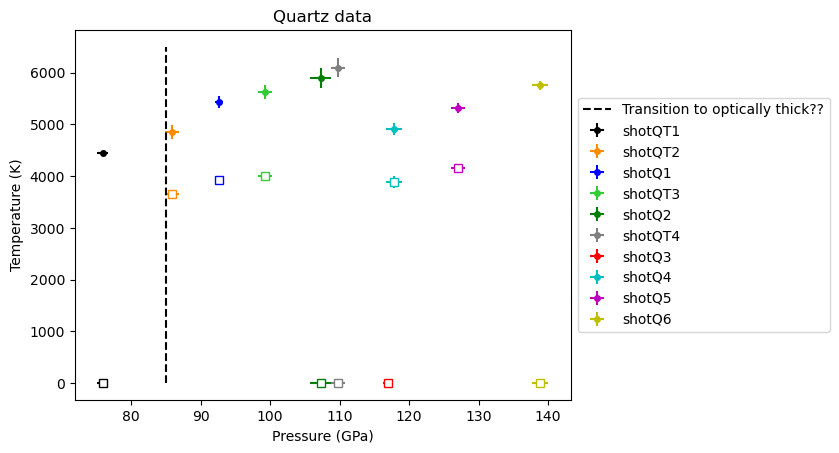

Shot#, rho (g/cm3), rho_err (g/cm34)
shotQT1 0 0
shotQT2 0 0
shotQ1 4.987353683762183 0.037610113282535156
shotQT3 0 0
shotQ2 5.009825615276592 0.09068367611804515
shotQT4 0 0
shotQ3 4.9595041150347035 0.03160295889607868
shotQ4 5.020831326044129 0.06581573312475111
shotQ5 5.270036233381568 0.06283594773708923
shotQ6 5.236568456716325 0.061513063777399464


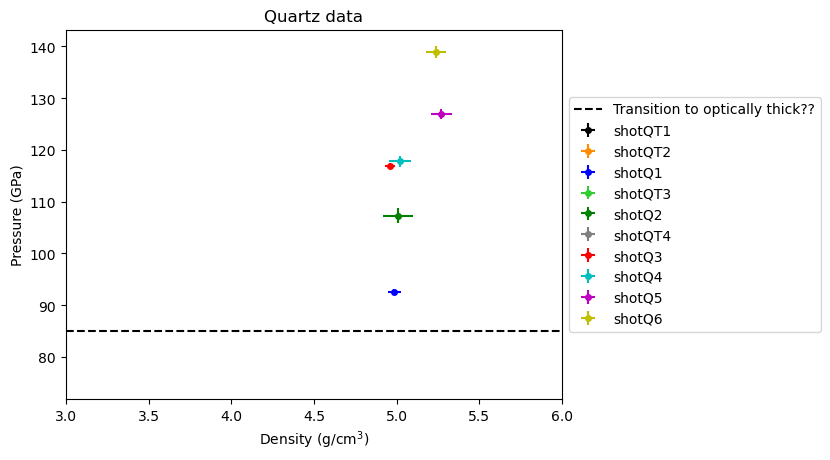

In [11]:
colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','brown','steelblue','darkviolet']
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

isort = np.argsort(qtz_p_list)
for i in isort:
    plt.errorbar(qtz_list[i].P[0],qtz_list[i].T[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=qtz_list[i].ref[0])
    plt.errorbar(qtz_list[i].P[0],qtz_list[i].T_rel[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
    print(qtz_list[i].ref[0],qtz_list[i].P[0],qtz_list[i].T[0],qtz_list[i].rem,qtz_list[i].uflyer[0],qtz_list[i].uflyer_std[0],qtz_list[i].us[0],qtz_list[i].us_std[0])
plt.plot([85,85],[0,6500],'k--',label='Transition to optically thick??')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Quartz data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

print('Shot#, rho (g/cm3), rho_err (g/cm34)')
for i in isort:
    plt.errorbar(qtz_list[i].rho[0],qtz_list[i].P[0],xerr=qtz_list[i].rho_std[0],yerr=qtz_list[i].P_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=qtz_list[i].ref[0])
    print(qtz_list[i].ref[0],qtz_list[i].rho[0],qtz_list[i].rho_std[0])
#plt.plot([73,73],[0,6500],'k--',label='Transition to optically thick??')
plt.ylabel('Pressure (GPa)')
plt.xlabel('Density (g/cm$^3$)')
plt.xlim(3,6)
plt.plot([3,6],[85,85],'k--',label='Transition to optically thick??')
plt.title('Quartz data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()


Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
shotFT1 58.9 4960.0 ['Boslough88'] 0.0 0.0 0.0 0.0
shotFT2 68.5 5110.0 ['Boslough88'] 0.0 0.0 0.0 0.0
shotFS1 74.12312128904783 4620.0 ['Boslough88'] 5.134 0.007 7.98 0.14
shotFS2 82.4743572355994 5080.0 ['Boslough88'] 5.445 0.009 8.42 0.11
shotFS3 95.43049295509688 5770.0 ['Boslough88'] 5.888 0.011 9.08 0.1
shotFS4 105.26740996000663 6530.0 ['Boslough88'] 6.285 0.007 9.4 0.1
shotFS5 112.32791663723798 7080.0 ['Boslough88'] 6.499 0.01 9.73 0.09


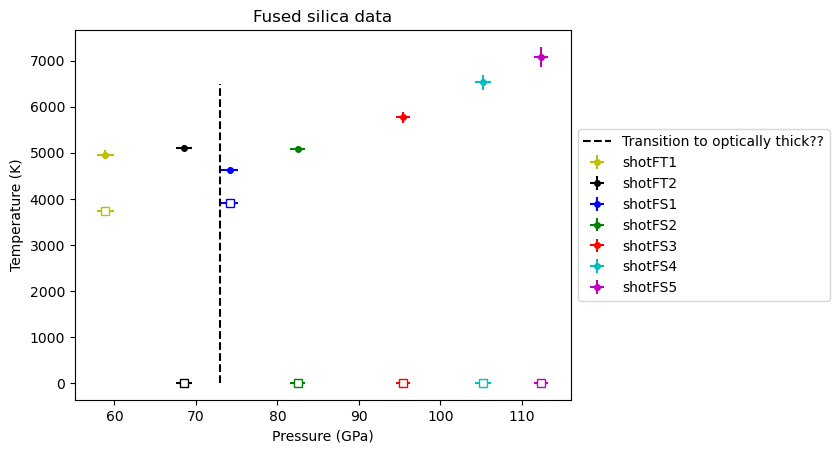

Shot#, rho (g/cm3), rho_err (g/cm34)
shotFT1 0 0
shotFT2 0 0
shotFS1 4.66666192961943 0.1079801890672354
shotFS2 4.665302807609329 0.08030000871225712
shotFS3 4.642392604347714 0.0675517571535518
shotFS4 4.8054381609563475 0.07226555836429471
shotFS5 4.7751129430300585 0.061865528583059715


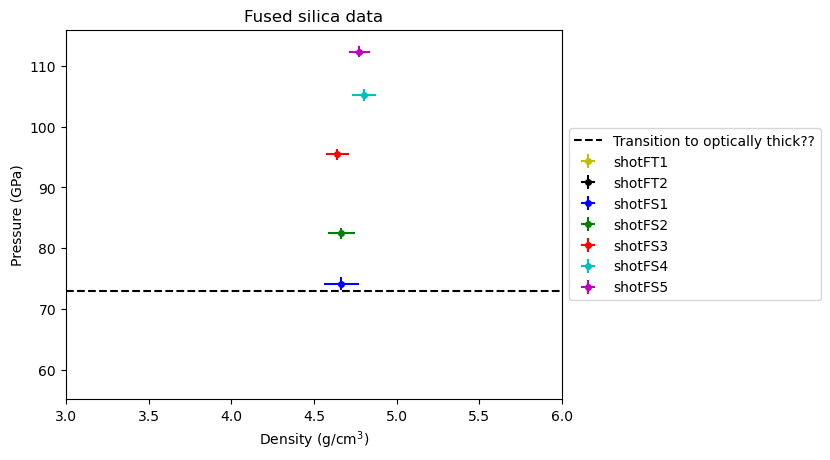

In [12]:
colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey']
isort = np.argsort(fs_p_list)
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')
for i in isort:
    plt.errorbar(fs_list[i].P[0],fs_list[i].T[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=fs_list[i].ref[0])
    plt.errorbar(fs_list[i].P[0],fs_list[i].T_rel[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
    print(fs_list[i].ref[0],fs_list[i].P[0],fs_list[i].T[0],fs_list[i].rem,fs_list[i].uflyer[0],fs_list[i].uflyer_std[0],fs_list[i].us[0],fs_list[i].us_std[0])
plt.plot([73,73],[0,6500],'k--',label='Transition to optically thick??')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Fused silica data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

print('Shot#, rho (g/cm3), rho_err (g/cm34)')
for i in isort:
    plt.errorbar(fs_list[i].rho[0],fs_list[i].P[0],xerr=fs_list[i].rho_std[0],yerr=fs_list[i].P_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=fs_list[i].ref[0])
    print(fs_list[i].ref[0],fs_list[i].rho[0],fs_list[i].rho_std[0])
plt.ylabel('Pressure (GPa)')
plt.xlabel('Density (g/cm$^3$)')
plt.xlim(3,6)
plt.plot([3,6],[73,73],'k--',label='Transition to optically thick??')
plt.title('Fused silica data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

   